# SPRINT 1 — LEITURA E DIAGNÓSTICO

In [1]:
from google.colab import files
uploaded = files.upload()

import pandas as pd

nome_arquivo = next(iter(uploaded))

df_original = pd.read_csv(nome_arquivo, sep=';')

Saving Base Varejo.csv to Base Varejo.csv


In [2]:
# Leitura da base

display(df_original.head())

,DATA,CO_ID,CL_ID,CL_GENERO,CL_EC,CL_FHL,CL_SEG,PR_ID,PR_CAT,PR_NOME,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13
0,01/02/2019,1000,534,M,4,1,C,67,BEBIDAS,REFRIGERANTE GUARANA,NaN,NaN,NaN,NaN
1,01/02/2019,1000,534,M,4,1,C,70,BEBIDAS,REFRIGERANTE OUTROS,NaN,NaN,NaN,NaN
2,01/02/2019,1000,534,M,4,1,C,178,HIGIENE,LENCO UMEDECIDO,NaN,NaN,NaN,NaN
3,01/02/2019,1000,534,M,4,1,C,4,ALIMENTOS,ABACAXI,NaN,NaN,NaN,NaN
4,01/02/2019,1000,534,M,4,1,C,175,LIMPEZA,LIMPADOR MULTIUSO,NaN,NaN,NaN,NaN


In [3]:
# Tamanho da base e conhecer as colunas

print("Dimensões: ", df_original.shape)
print("Colunas: ", df_original.columns.tolist())

Dimensões:  (830000, 14)
Colunas:  ['DATA', 'CO_ID', 'CL_ID', 'CL_GENERO', 'CL_EC', 'CL_FHL', 'CL_SEG', 'PR_ID', 'PR_CAT', 'PR_NOME', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13']


In [4]:
# Info da base
df_original.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 830000 entries, 0 to 829999
Data columns (total 14 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   DATA         830000 non-null  object 
 1   CO_ID        830000 non-null  int64  
 2   CL_ID        830000 non-null  int64  
 3   CL_GENERO    830000 non-null  object 
 4   CL_EC        830000 non-null  int64  
 5   CL_FHL       830000 non-null  int64  
 6   CL_SEG       830000 non-null  object 
 7   PR_ID        830000 non-null  int64  
 8   PR_CAT       830000 non-null  object 
 9   PR_NOME      830000 non-null  object 
 10  Unnamed: 10  0 non-null       float64
 11  Unnamed: 11  0 non-null       float64
 12  Unnamed: 12  0 non-null       float64
 13  Unnamed: 13  0 non-null       float64
dtypes: float64(4), int64(5), object(5)
memory usage: 88.7+ MB


In [5]:
# Remover colunas que possuem apenas valores nulos

df_original.dropna(axis=1, how='all', inplace=True)

In [6]:
# Renomear colunas

df_original.rename(columns={
    'DATA': 'data',
    'CO_ID': 'id_compra',
    'CL_ID': 'id_cliente',
    'CL_GENERO': 'genero',
    'CL_EC': 'estado_civil',
    'CL_FHL': 'filhos',
    'CL_SEG': 'segmento',
    'PR_ID': 'id_produto',
    'PR_CAT': 'categoria',
    'PR_NOME': 'nome_produto'
}, inplace=True)

# Verificar colunas
print(df_original.columns.tolist())

['data', 'id_compra', 'id_cliente', 'genero', 'estado_civil', 'filhos', 'segmento', 'id_produto', 'categoria', 'nome_produto']


In [7]:
# Valores nulos

display(df_original.isna().sum())

# Duplicatas
print(
    "Duplicatas completas excedentes:",
    df_original.duplicated().sum()
)


,0
data,0
id_compra,0
id_cliente,0
genero,0
estado_civil,0
filhos,0
segmento,0
id_produto,0
categoria,0
nome_produto,0


Duplicatas completas excedentes: 96553


In [8]:
# Visualização das duplicatas

df_original[df_original.duplicated()]

,data,id_compra,id_cliente,genero,estado_civil,filhos,segmento,id_produto,categoria,nome_produto
19,01/02/2019,1000,534,M,4,1,C,13,ALIMENTOS,BANANA
40,01/02/2019,1000,534,M,4,1,C,4,ALIMENTOS,ABACAXI
46,01/02/2019,1000,534,M,4,1,C,11,ALIMENTOS,AZEITE
49,01/02/2019,1000,534,M,4,1,C,69,BEBIDAS,REFRIGERANTE LIMaO
50,01/02/2019,1000,534,M,4,1,C,218,ALIMENTOS,BIFE DE COXAO MOLE
...,...,...,...,...,...,...,...,...,...,...
829989,19/08/2022,919822,155,F,2,0,B,34,ALIMENTOS,KETCHUP
829992,19/08/2022,919822,155,F,2,0,B,30,ALIMENTOS,FILE DE PEIXE
829995,19/08/2022,919822,155,F,2,0,B,183,ALIMENTOS,KETCHUP
829996,19/08/2022,919822,155,F,2,0,B,56,ALIMENTOS,QUEIJO MUSSARELA


In [9]:
# Visualizando registros de clientes

print(
    "Compras distintas:",
    df_original["id_compra"].nunique()
)

print(
    "Clientes distintos:",
    df_original["id_cliente"].nunique()
)

Compras distintas: 18471
Clientes distintos: 1000


In [12]:
# Inconsistências textuais

# Para espaços

colunas_texto = [
    "genero",
    "estado_civil",
    "segmento",
    "categoria",
    "nome_produto",

]

for coluna in colunas_texto:
    quantidade_em_branco = (
        df_original[coluna]
        .astype("string")
        .str.strip()
        .eq("")
        .sum()
    )

    print(coluna, ":", quantidade_em_branco)

genero : 0
estado_civil : 0
segmento : 0
categoria : 0
nome_produto : 0


In [13]:
# Diferenças de escrita

for coluna in ["id_compra", "id_cliente", "genero", "estado_civil", "segmento", "categoria", "nome_produto"]:
  print(coluna)
  print(df_original[coluna].unique())

id_compra
[  1000   1040   1078 ... 919716 919770 919822]
id_cliente
[ 534  279  290  323  957   49  906  653  842  616  406  576  652  453
  829  251  397  438   69  608  423   53  886  624   94  428   72  493
  497  164  689   99  866  801  340   52  574  328  466  296  149  458
  776  746   45  798  709  796  878  888  246  433  545  943  429   56
  922  305  236  193  927  594  333  199  973  686  523  225   82  362
  394  243  160   79  151  933    6  322  663  459  761  384  707  954
  227  804  462  283   25  348  757   44  332   38  257    4  865  982
  516  443  996  847  408  369  502  163  171  597  289  521  770   42
  517  628   59  418  113  756  506  991  773  525  174  498  921  916
   96  110  740  780  350  768  892   75  880  583  580  539  560  645
  978  831  830  651  814  815  301  122  750  802  351  304  143  935
  512  552  759  487  691  828  425  659   17  464  742  884  325   83
  391  785  812  398  206  491  463  510  537  898  482  527    5   34
  971  5

In [14]:
# Investigar registros #N/D em categoria

df_original["categoria"].value_counts(dropna=False)


,count
categoria,
ALIMENTOS,434767
HIGIENE,155574
LIMPEZA,145754
BEBIDAS,43299
PET,32399
ACESSORIOS,14557
#N/D,3650


In [15]:
df_original.loc[
    df_original["categoria"] == "#N/D"
].head()

,data,id_compra,id_cliente,genero,estado_civil,filhos,segmento,id_produto,categoria,nome_produto
82,01/02/2019,1078,290,F,1,0,B,107,#N/D,#N/D
223,01/02/2019,1103,957,M,2,3,B,107,#N/D,#N/D
640,01/02/2019,1482,453,F,1,0,B,107,#N/D,#N/D
857,01/02/2019,1683,438,F,1,0,B,107,#N/D,#N/D
917,01/02/2019,1793,608,F,3,0,C,107,#N/D,#N/D


### Conclusão de leitura e diagnóstico

| Verificação | Resultado |
|---|---|
| Dimensões | 830000 linhas 14 colunas |
| Remoção de colunas nulas | 4 |
| Dimensãoes após a remoção | 830000 linhas e 10 colunas |
| `id_compra` distintos | 18471 |
| `id_cliente` distintos | 1000 |
| Duplicatas completas excedentes | 96553 |
| Valores nulos | 0 |
| Inconsistências na coluna `categoria`| valores #N/D |


# SPRINT 2 — LIMPEZA E PADRONIZAÇÃO

Após análise inicial, verificou-se a existência de quatro colunas nulas que foram excluídas.
As duplicatas excedentes não serão escluídas pois trata-se de compras diversas de um mesmo cliente.
Para melhor legibilidade, as colunas foram renomeadas.
Registros #N/D em `categoria`  e `nome_produto` não serão removidos mesmo que não seja possível utilizá-los em sua respectiva análise. Eles ainda podem ser úteis para analisar clientes e compras.

# SPRINT 3 — FUNÇÕES

In [16]:
# Função de tratamento de dados

def tratar_dados(df):

    df = df.copy()

    # Padronizar textos
    colunas_texto = [
        "genero",
        "estado_civil",
        "segmento",
        "categoria",
        "nome_produto"
    ]

    for coluna in colunas_texto:
        df[coluna] = (
            df[coluna]
            .astype("string")
            .str.strip()
            .str.lower()
        )

  # Tratar categorias não identificadas

    df["categoria"] = df["categoria"].replace(
    "#N/D",
    "não informado"
)

  # Tratar nomes de produtos ausentes

    df["nome_produto"] = df["nome_produto"].replace(
    "#N/D",
    "não informado"
)

  # Tratar valores nulos

    df[["categoria", "nome_produto"]] = (
       df[["categoria", "nome_produto"]]
       .fillna("não informado")
)

    # Converter data
    df["data"] = pd.to_datetime(
        df["data"],
        errors="coerce"
    )

    return df


In [17]:
# Função para gerar resumo

def gerar_resumo(df):

    resumo = {
        "Total de registros": len(df),

        "Clientes distintos": df["id_cliente"].nunique(),

        "Compras distintas": df["id_compra"].nunique(),

        "Produtos distintos": df["id_produto"].nunique(),

        "Duplicatas completas": df.duplicated().sum(),

        "Data inicial": df["data"].min(),

        "Data final": df["data"].max()
    }

    return pd.Series(resumo)

In [18]:
# Aplicar tratamento
df_tratado = tratar_dados(df_original)

# Gerar resumo
resumo = gerar_resumo(df_tratado)

# Exibir resumo
display(resumo)

,0
Total de registros,830000
Clientes distintos,1000
Compras distintas,18471
Produtos distintos,229
Duplicatas completas,96553
Data inicial,2019-01-02 00:00:00
Data final,2022-08-12 00:00:00


# SPRINT 4 — ANÁLISE


In [19]:
# Filtro de clientes com filhos

df_com_filhos = df_tratado.loc[
    df_tratado["filhos"] > 0
]

display(df_com_filhos.head())

,data,id_compra,id_cliente,genero,estado_civil,filhos,segmento,id_produto,categoria,nome_produto
0,2019-01-02,1000,534,m,4,1,c,67,bebidas,refrigerante guarana
1,2019-01-02,1000,534,m,4,1,c,70,bebidas,refrigerante outros
2,2019-01-02,1000,534,m,4,1,c,178,higiene,lenco umedecido
3,2019-01-02,1000,534,m,4,1,c,4,alimentos,abacaxi
4,2019-01-02,1000,534,m,4,1,c,175,limpeza,limpador multiuso


In [20]:
df_com_filhos["id_cliente"].nunique()

473

In [22]:
# Estatísticas

clientes_unicos = (
    df_tratado[
        ["id_cliente", "filhos"]
    ]
    .drop_duplicates(subset="id_cliente")
)

print("Quantidade de valores válidos:", clientes_unicos["filhos"].count())

print("Média de filhos:", round(clientes_unicos["filhos"].mean(), 2))

print("Mínimo de filhos:", clientes_unicos["filhos"].min())

print("Máximo de filhos:", clientes_unicos["filhos"].max())

Quantidade de valores válidos: 1000
Média de filhos: 1.14
Mínimo de filhos: 0
Máximo de filhos: 4


In [23]:
# Agrupamento de filhos por gênero

filhos_genero = (
    df_tratado[
        ["id_cliente", "genero", "filhos"]
    ]
    .drop_duplicates(subset="id_cliente")
    .groupby("genero")["filhos"]
    .sum()
    .reset_index(name="total_filhos")
    .sort_values("total_filhos", ascending=False)
)

display(filhos_genero)

,genero,total_filhos
1,m,575
0,f,561


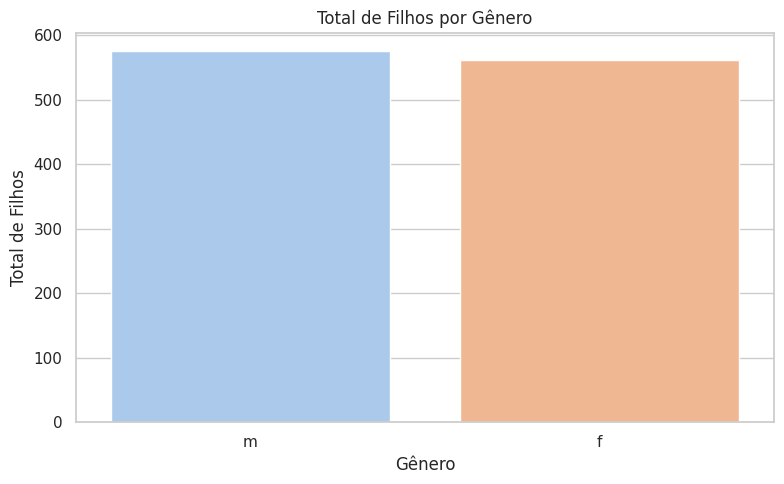

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=filhos_genero,
    x="genero",
    y="total_filhos",
    hue="genero",
    palette="pastel",
    legend=False
)

plt.title("Total de Filhos por Gênero")
plt.xlabel("Gênero")
plt.ylabel("Total de Filhos")

plt.tight_layout()
plt.show()

In [25]:
# Agrupamento de filhos por estado civil

total_filhos_estado_civil = (
    df_tratado[
        ["id_cliente", "estado_civil", "filhos"]
    ]
    .drop_duplicates(subset="id_cliente")
    .groupby("estado_civil")["filhos"]
    .sum()
    .reset_index(name="total_filhos")
    .sort_values("total_filhos", ascending=False)
)

display(total_filhos_estado_civil)

,estado_civil,total_filhos
2,3,299
1,2,297
0,1,295
3,4,203
4,5,42


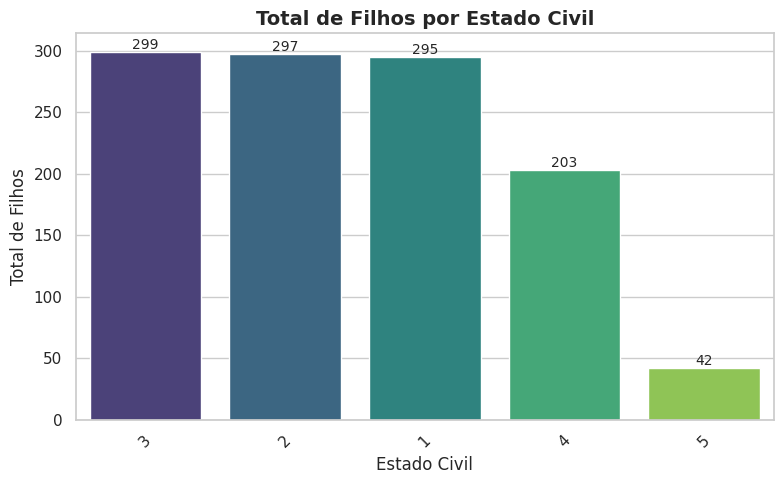

In [26]:
ax = sns.barplot(
    data=total_filhos_estado_civil,
    x="estado_civil",
    y="total_filhos",
    hue="estado_civil",
    palette="viridis",
    legend=False
)

# Adicionar os valores acima das barras
for p in ax.patches:
    ax.annotate(
        f'{int(p.get_height())}',
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.title("Total de Filhos por Estado Civil", fontsize=14, fontweight="bold")
plt.xlabel("Estado Civil")
plt.ylabel("Total de Filhos")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [28]:
# Agrupamento de filhos por segmento

total_filhos_segmento = (
    df_tratado[
        ["id_cliente", "segmento", "filhos"]
    ]
    .drop_duplicates(subset="id_cliente")
    .groupby("segmento")["filhos"]
    .sum()
    .reset_index(name="total_filhos")
)

display(total_filhos_segmento)

,segmento,total_filhos
0,a,89
1,b,724
2,c,323


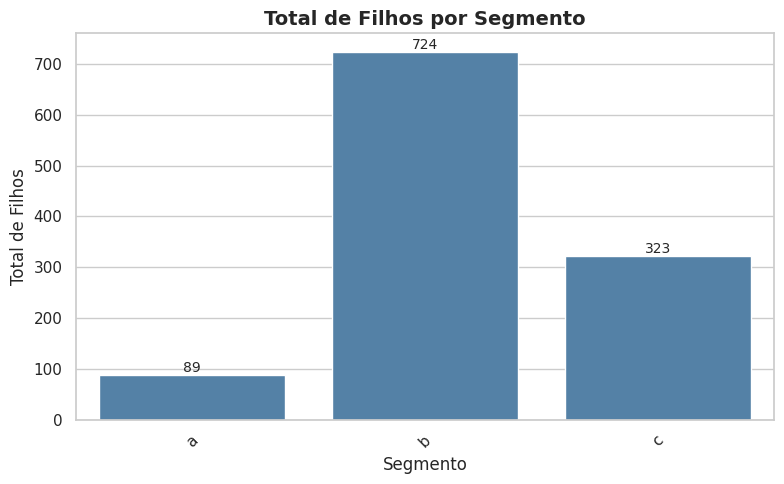

In [29]:
ax = sns.barplot(
    data=total_filhos_segmento,
    x="segmento",
    y="total_filhos",
    color="steelblue"
)

# Adicionar rótulos
for p in ax.patches:
    ax.annotate(
        f'{int(p.get_height())}',
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.title("Total de Filhos por Segmento", fontsize=14, fontweight="bold")
plt.xlabel("Segmento")
plt.ylabel("Total de Filhos")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

# SPRINT 5 — EXPORTAÇÃO E CONCLUSÕES


In [30]:
df_tratado.to_csv(
    "varejo_simulado_limpo.csv",
    index=False
)

In [31]:
conferencia = pd.read_csv(
    "varejo_simulado_limpo.csv"
)

print(conferencia.shape)
print(conferencia.columns.tolist())

(830000, 10)
['data', 'id_compra', 'id_cliente', 'genero', 'estado_civil', 'filhos', 'segmento', 'id_produto', 'categoria', 'nome_produto']


# Conclusão

1. A base inicial continha 830000 linhas e 14 colunas. Foram removidas 4 colunas pois seus valores eram nulos.

2. As colunas foram renomeadas para maior compreensão.

3. Tratamos os valores nulos, inconsistências textuais e diferenças na escrita.

4. Verificados valores ausentes nas colunas `categoria` e `nome_produto`. Os mesmos não foram excluídos pois poderiam impactar o restante das análises.

5. Encontradas 96553 duplicatas excedentes que não foram excluídas por se tratar de compras de mesmo cliente.

6. Dentre os 1000 clientes distintos, 473 possuem ao menos um filho. O Maior número de filhos encontado foi quatro. O menor número de filhos foi encontrado em solteiros e viúvos. O segmento com maior número de filhos foi o "B".

**Recomendação**
Verificar as ausências de valores nas colunas `categoria` e `nome_produto`, para que tenhamos uma análise completa dos dados.

**Limitação**
Pela falta de dados nas colunas `categoria` e `nome_produto`, houve uma limitaçao de análise mais aprofundada e completa desta base.